**Họ và tên:** Thái Anh Lạc | **MSSV:** 089206000860 | **Mã lớp HP:** 012012204103

# BÀI THỰC HÀNH PHẦN 1: KHÁM PHÁ, PHÂN RÃ VÀ KIỂM ĐỊNH TÍNH DỪNG
### Đề tài: Phân tích Chuỗi thời gian Dữ liệu COVID-19 Toàn cầu (CSSE JHU)
---
Nội dung bài thực hành phần 1:
* **Bước 1:** Khởi tạo môi trường & Tải dữ liệu dịch bệnh COVID-19 toàn cầu.
* **Bước 2:** EDA cơ bản & Tiền xử lý dữ liệu (Xử lý Datetime, Chuyển đổi Cumulative sang Daily, Missing values, Outliers).
* **Bước 3:** EDA chuyên sâu:
  * Trực quan hóa diễn biến chuỗi thời gian toàn cầu.
  * Phân rã chuỗi thời gian (Decomposition: Level, Trend, Seasonality, Noise).
  * Phân tích chu kỳ tuần và tháng qua Biểu đồ hộp (Day-of-Week & Monthly Boxplot).
  * Phân tích hàm tự tương quan ACF & PACF.
  * Kiểm định phân phối chuẩn của phần dư (Residuals Normality & Q-Q Plot).
* **Bước 4:** Kiểm tra tính dừng (Rolling Statistics, Kiểm định ADF Test) & Các kỹ thuật biến đổi làm dừng chuỗi (Sai phân bậc 1, Sai phân mùa vụ, Log scale, Moving Average Smoothing).


## 1. KHỞI TẠO MÔI TRƯỜNG & TẢI DỮ LIỆU
Các thư viện sử dụng trong bài thực hành:
* `pandas`, `numpy`: Thao tác, làm sạch và xử lý mảng số và dữ liệu chuỗi thời gian.
* `matplotlib.pyplot`, `seaborn`: Trực quan hóa dữ liệu với hệ thống đồ thị thống kê.
* `scipy.stats`: Cung cấp biểu đồ Q-Q Plot và kiểm định phân phối chuẩn Jarque-Bera.
* `statsmodels`: Cung cấp các thuật toán phân rã chuỗi `seasonal_decompose`, kiểm định nghiệm đơn vị `adfuller` (ADF test), và hàm tự tương quan `plot_acf`, `plot_pacf`.


In [1]:
import warnings
import os
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import scipy.stats as stats

import statsmodels.api as sm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Cấu hình hiển thị và phong cách đồ thị
warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 12

print("Đã khởi tạo thành công tất cả các thư viện cần thiết!")


Đã khởi tạo thành công tất cả các thư viện cần thiết!


### 1.1 Tải bộ dữ liệu COVID-19 Confirmed Global (Johns Hopkins University)
Bộ dữ liệu `time_series_covid19_confirmed_global.csv` theo dõi số ca nhiễm COVID-19 tích lũy hàng ngày trên toàn thế giới từ ngày 22/01/2020 đến tháng 03/2023.


In [2]:
# Đường dẫn file dữ liệu (ưu tiên file local, nếu chưa có sẽ tự động tải từ GitHub)
csv_filename = "time_series_covid19_confirmed_global.csv"
github_url = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

if not os.path.exists(csv_filename):
    print("Đang tải dữ liệu từ GitHub CSSEGISandData...")
    urllib.request.urlretrieve(github_url, csv_filename)
    print("Tải dữ liệu hoàn tất!")
else:
    print(f"Đã tìm thấy file dữ liệu tại thư mục: {csv_filename}")

# Đọc file CSV
raw_df = pd.read_csv(csv_filename)
print(f"Kích thước bảng dữ liệu gốc: {raw_df.shape[0]} quốc gia/vùng lãnh thổ, {raw_df.shape[1]} cột.")
raw_df.head(5)


Đã tìm thấy file dữ liệu tại thư mục: time_series_covid19_confirmed_global.csv
Kích thước bảng dữ liệu gốc: 289 quốc gia/vùng lãnh thổ, 1147 cột.


,Province/State,Country/Region,Lat,Long,1/22/20,1/23/20,1/24/20,1/25/20,1/26/20,1/27/20,...,2/28/23,3/1/23,3/2/23,3/3/23,3/4/23,3/5/23,3/6/23,3/7/23,3/8/23,3/9/23
0,NaN,Afghanistan,33.93911,67.709953,0,0,0,0,0,0,...,209322,209340,209358,209362,209369,209390,209406,209436,209451,209451
1,NaN,Albania,41.15330,20.168300,0,0,0,0,0,0,...,334391,334408,334408,334427,334427,334427,334427,334427,334443,334457
2,NaN,Algeria,28.03390,1.659600,0,0,0,0,0,0,...,271441,271448,271463,271469,271469,271477,271477,271490,271494,271496
3,NaN,Andorra,42.50630,1.521800,0,0,0,0,0,0,...,47866,47875,47875,47875,47875,47875,47875,47875,47890,47890
4,NaN,Angola,-11.20270,17.873900,0,0,0,0,0,0,...,105255,105277,105277,105277,105277,105277,105277,105277,105288,105288


## 2. BƯỚC 2: EDA CƠ BẢN & TIỀN XỬ LÝ DỮ LIỆU
Bảng dữ liệu gốc ở định dạng Wide Format (mỗi ngày là một cột ngang từ cột thứ 4 trở đi). Quy trình xử lý gồm:
1. **Chuẩn hóa trục thời gian:** Chuyển các cột ngày tháng sang kiểu `pd.to_datetime` với định dạng `%m/%d/%y`.
2. **Tổng hợp dữ liệu toàn cầu:** Cộng dồn tất cả các quốc gia theo từng ngày để tạo chuỗi số ca tích lũy toàn cầu (`Cumulative_Cases`).
3. **Chuyển đổi số ca tích lũy sang số ca mới mỗi ngày:**
   * Sử dụng hàm sai phân `.diff()`: $\text{Daily}_t = \text{Cumulative}_t - \text{Cumulative}_{t-1}$.
   * Xử lý các giá trị âm bằng `.clip(lower=0)` để đảm bảo tính thực tế y tế.
4. **Kiểm tra missing values & Tính liên tục của mốc thời gian.**
5. **Nhận diện và xử lý ngoại lai (Outliers) bằng kỹ thuật Rolling Mean.**


In [3]:
# Tách các cột ngày tháng (từ cột thứ 4 trở đi)
date_columns = raw_df.columns[4:]

# Gom nhóm tổng số ca tích lũy toàn cầu theo từng ngày
global_cumulative = raw_df[date_columns].sum(axis=0)
global_cumulative.index = pd.to_datetime(global_cumulative.index, format='%m/%d/%y')

# Tạo DataFrame chuỗi thời gian chính
covid_df = pd.DataFrame({'Cumulative_Cases': global_cumulative})

# Đảm bảo tần suất lấy mẫu liên tục theo ngày ('D')
covid_df = covid_df.asfreq('D')

print(f"Khoảng thời gian khảo sát: Từ {covid_df.index.min().strftime('%d/%m/%Y')} đến {covid_df.index.max().strftime('%d/%m/%Y')}")
print(f"Tổng số ngày quan sát: {len(covid_df)} ngày.")
print("Kiểm tra giá trị thiếu (Missing Values):")
print(covid_df.isna().sum())


Khoảng thời gian khảo sát: Từ 22/01/2020 đến 09/03/2023
Tổng số ngày quan sát: 1143 ngày.
Kiểm tra giá trị thiếu (Missing Values):
Cumulative_Cases    0
dtype: int64


### 2.1 Chuyển đổi từ số ca tích lũy (Cumulative) sang số ca mới mỗi ngày (Daily Cases)
* **Lý do cần chuyển đổi:** Số ca tích lũy luôn tăng đơn điệu, che lấp toàn bộ các chu kỳ tuần và biến động của các làn sóng dịch. Số ca nhiễm mới mỗi ngày phản ánh chính xác tốc độ lây lan của virus.
* **Xử lý số âm:** Do các đợt điều chỉnh hồi tố số liệu y tế ở một số quốc gia, có những ngày số liệu bị trừ bớt khiến sai phân bị âm. Ta dùng `.clip(lower=0)` để chuẩn hóa.


In [4]:
# Tính số ca nhiễm mới mỗi ngày bằng sai phân bậc 1
covid_df['Daily_Cases'] = covid_df['Cumulative_Cases'].diff().fillna(0).clip(lower=0)

# Tạo thêm số ca trung bình trượt 7 ngày (7-day Rolling Mean) để lọc nhiễu cuối tuần
covid_df['Daily_Cases_7d_MA'] = covid_df['Daily_Cases'].rolling(window=7, min_periods=1).mean()

print("Thống kê mô tả số ca nhiễm mới hàng ngày toàn cầu:")
display(covid_df[['Cumulative_Cases', 'Daily_Cases', 'Daily_Cases_7d_MA']].describe().round(0))


Thống kê mô tả số ca nhiễm mới hàng ngày toàn cầu:


,Cumulative_Cases,Daily_Cases,Daily_Cases_7d_MA
count,1143.0,1143.0,1143.0
mean,277261852.0,591924.0,591572.0
std,239775690.0,595648.0,569698.0
min,557.0,0.0,0.0
25%,47426060.0,265196.0,285877.0
50%,207815449.0,472523.0,487367.0
75%,528830664.0,676774.0,646157.0
max,676570149.0,4083281.0,3436897.0


### 2.2 Nhận diện và Xử lý ngoại lai (Outliers)
Trong chuỗi thời gian dịch tễ, ngoại lai thường sinh ra do báo cáo dồn số liệu sau các kỳ nghỉ lễ hoặc khi thay đổi tiêu chí xét nghiệm.
Ta sử dụng biểu đồ phân phối Histogram, Boxplot và khoảng tứ phân vị (IQR) để phát hiện các ngày có số ca tăng vọt bất thường.


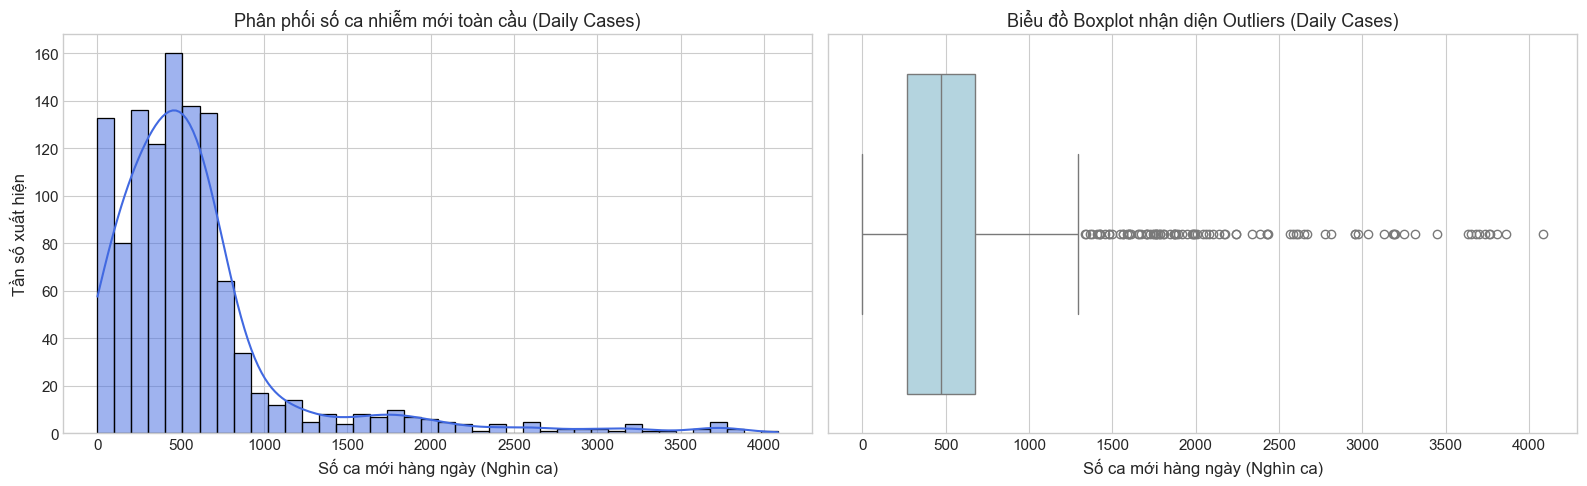

Ngưỡng trên IQR: 1,294,141 ca/ngày. Số ngày vượt ngưỡng ngoại lai: 93 ngày (chủ yếu tập trung ở giai đoạn đầu năm 2022).


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# 1. Histogram Daily Cases
sns.histplot(covid_df['Daily_Cases'] / 1e3, bins=40, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title('Phân phối số ca nhiễm mới toàn cầu (Daily Cases)')
axes[0].set_xlabel('Số ca mới hàng ngày (Nghìn ca)')
axes[0].set_ylabel('Tần số xuất hiện')

# 2. Boxplot Daily Cases
sns.boxplot(x=covid_df['Daily_Cases'] / 1e3, ax=axes[1], color='lightblue')
axes[1].set_title('Biểu đồ Boxplot nhận diện Outliers (Daily Cases)')
axes[1].set_xlabel('Số ca mới hàng ngày (Nghìn ca)')

plt.tight_layout()
plt.show()

# Tính ngưỡng Outlier theo IQR
Q1 = covid_df['Daily_Cases'].quantile(0.25)
Q3 = covid_df['Daily_Cases'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR
outliers_count = (covid_df['Daily_Cases'] > upper_bound).sum()
print(f"Ngưỡng trên IQR: {upper_bound:,.0f} ca/ngày. Số ngày vượt ngưỡng ngoại lai: {outliers_count} ngày (chủ yếu tập trung ở giai đoạn đầu năm 2022).")


## 3. BƯỚC 3: EDA CHUYÊN SÂU (TIME SERIES DECOMPOSITION, CHU KỲ TUẦN/THÁNG & ACF/PACF)
Quy trình phân tích chuyên sâu gồm:
1. **Trực quan hóa diễn biến dịch bệnh:** Đánh giá số ca tích lũy và số ca mới hàng ngày thuần túy theo số liệu thực tế.
2. **Phân rã chuỗi thời gian (Decomposition):** Bóc tách thành phần Level, Trend, Seasonality, Residual với chu kỳ $s = 7$ ngày.
3. **Phân tích phân phối theo Thứ và theo Tháng (Day-of-Week & Monthly Boxplot):** Minh chứng trực quan cho hiệu ứng cuối tuần và tính thời vụ.
4. **Phân tích hàm tự tương quan (ACF) và tự tương quan riêng phần (PACF):** Đánh giá các độ trễ có ý nghĩa thống kê.
5. **Kiểm định tính phân phối chuẩn của phần dư (Residuals Normality & Q-Q Plot):** Đánh giá giả định nhiễu trắng.


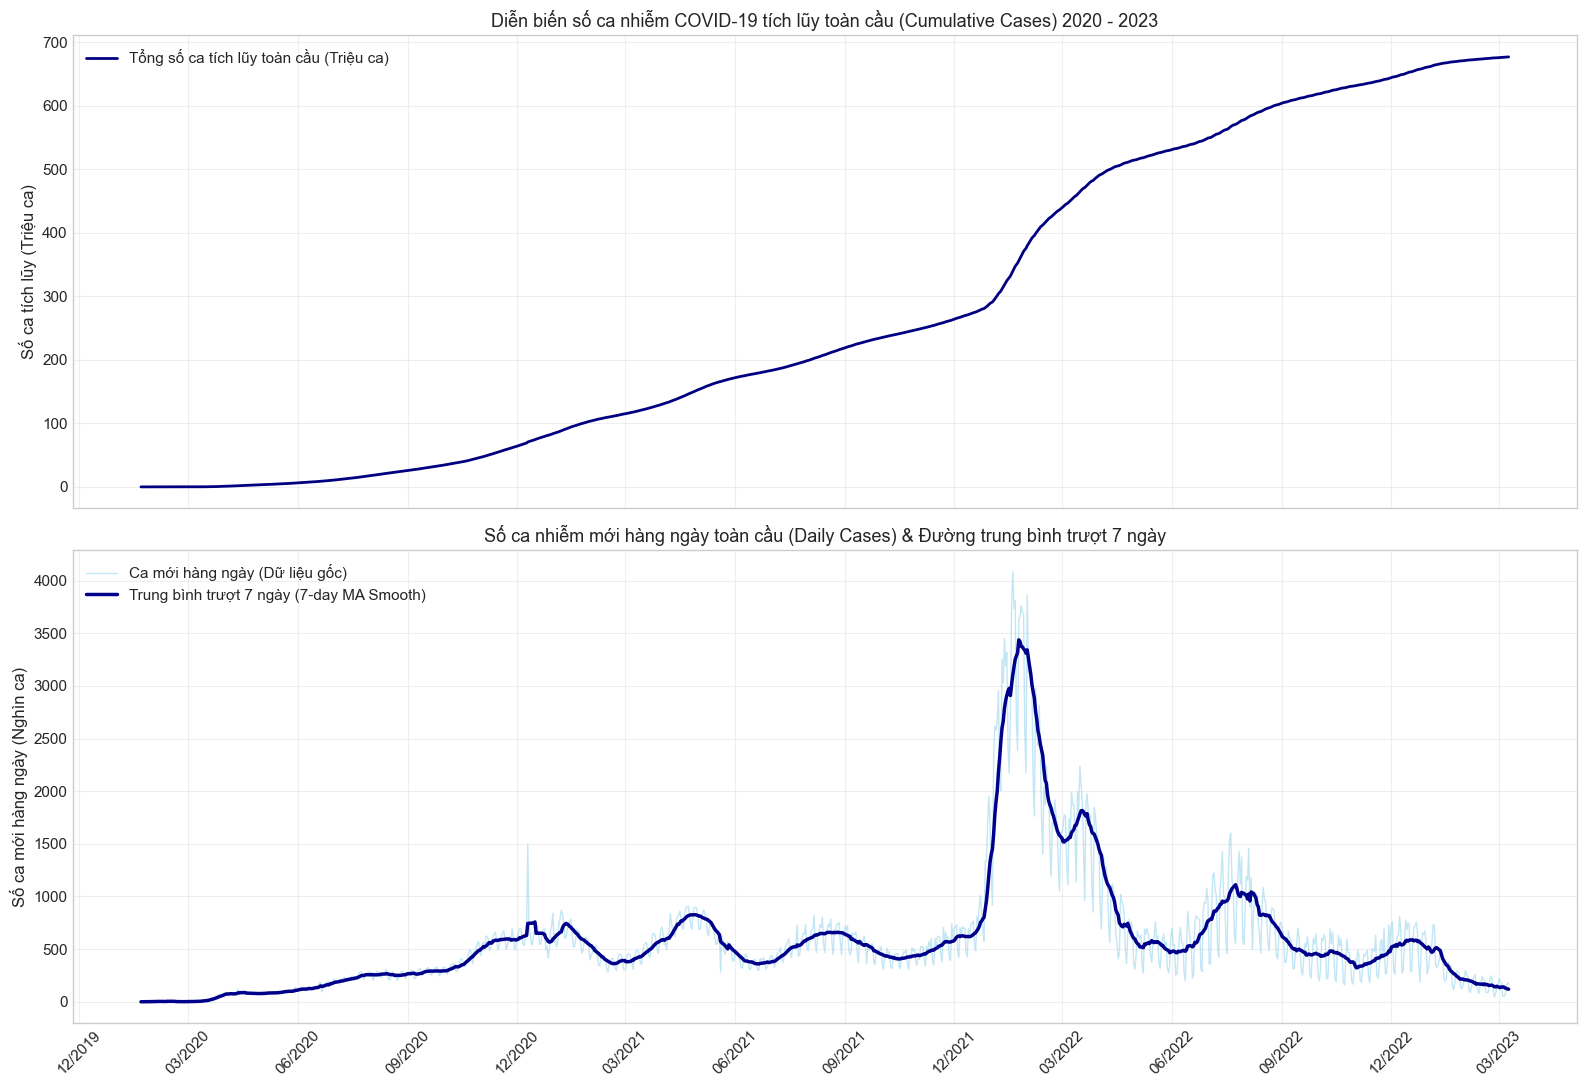

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(16, 11), sharex=True)

# Đồ thị 1: Số ca tích lũy toàn cầu
axes[0].plot(covid_df.index, covid_df['Cumulative_Cases'] / 1e6, label='Tổng số ca tích lũy toàn cầu (Triệu ca)', color='navy', lw=2)
axes[0].set_ylabel('Số ca tích lũy (Triệu ca)')
axes[0].set_title('Diễn biến số ca nhiễm COVID-19 tích lũy toàn cầu (Cumulative Cases) 2020 - 2023')
axes[0].legend(loc='upper left')
axes[0].grid(True, alpha=0.3)

# Đồ thị 2: Số ca mới hàng ngày kèm đường trung bình trượt 7 ngày thuần túy số liệu
axes[1].plot(covid_df.index, covid_df['Daily_Cases'] / 1e3, label='Ca mới hàng ngày (Dữ liệu gốc)', color='skyblue', alpha=0.5, lw=1)
axes[1].plot(covid_df.index, covid_df['Daily_Cases_7d_MA'] / 1e3, label='Trung bình trượt 7 ngày (7-day MA Smooth)', color='darkblue', lw=2.5)

axes[1].set_ylabel('Số ca mới hàng ngày (Nghìn ca)')
axes[1].set_title('Số ca nhiễm mới hàng ngày toàn cầu (Daily Cases) & Đường trung bình trượt 7 ngày')
axes[1].legend(loc='upper left')
axes[1].grid(True, alpha=0.3)

# Định dạng hiển thị trục ngày tháng
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### 3.1 Phân rã chuỗi thời gian (Time Series Decomposition)
Ta tiến hành phân rã chuỗi số ca nhiễm mới hàng ngày toàn cầu `Daily_Cases` với chu kỳ tuần $s = 7$ ngày (`period=7`):
* **Observed ($y_t$):** Chuỗi giá trị thực tế quan sát được ban đầu.
* **Trend ($T_t$):** Xu hướng dịch chuyển dài hạn, phản ánh các làn sóng bùng phát và thoái trào dịch bệnh.
* **Seasonality ($S_t$):** Tính chu kỳ theo tuần lặp lại đều đặn do quy trình báo cáo xét nghiệm y tế.
* **Residual / Noise ($R_t$):** Phần dư ngẫu nhiên sau khi đã tách bỏ xu hướng và mùa vụ.


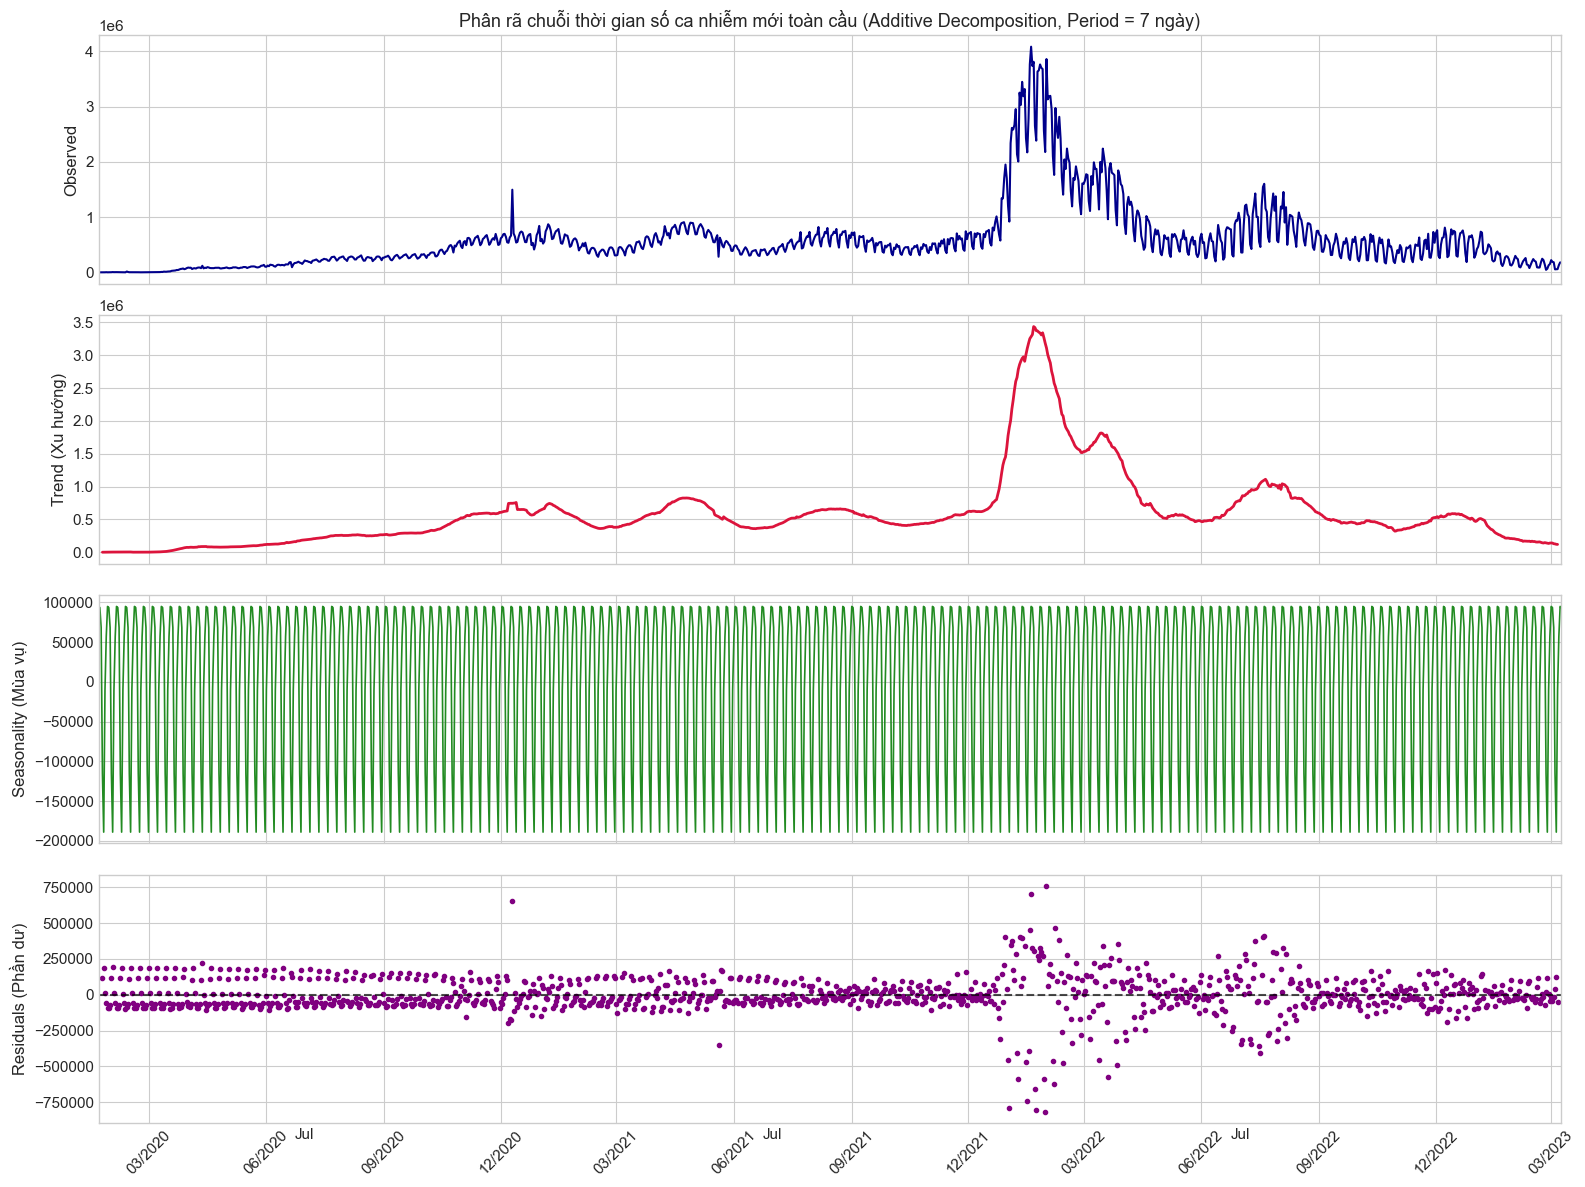

In [7]:
# Thực hiện phân rã theo mô hình Cộng (Additive Model) với chu kỳ tuần 7 ngày
decomposition = seasonal_decompose(covid_df['Daily_Cases'], model='additive', period=7)

fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

decomposition.observed.plot(ax=axes[0], color='darkblue', lw=1.5)
axes[0].set_ylabel('Observed')
axes[0].set_title('Phân rã chuỗi thời gian số ca nhiễm mới toàn cầu (Additive Decomposition, Period = 7 ngày)')

decomposition.trend.plot(ax=axes[1], color='crimson', lw=2)
axes[1].set_ylabel('Trend (Xu hướng)')

decomposition.seasonal.plot(ax=axes[2], color='forestgreen', lw=1.2)
axes[2].set_ylabel('Seasonality (Mùa vụ)')

decomposition.resid.plot(ax=axes[3], color='purple', lw=1, style='.')
axes[3].axhline(0, color='black', linestyle='--', alpha=0.7)
axes[3].set_ylabel('Residuals (Phần dư)')

axes[3].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


#### Nhận xét kết quả phân rã chuỗi:
1. **Trend (Xu hướng):** 
   * Năm 2020: Dịch bùng phát từng bước với các làn sóng nhỏ ban đầu.
   * Năm 2021: Xuất hiện các đợt dao động vừa phải quanh mức 500.000 đến 800.000 ca/ngày.
   * Đầu năm 2022 (Tháng 01 - 03/2022): Đỉnh bùng nổ kỷ lục toàn cầu với số ca mới có ngày vượt 3.5 triệu ca/ngày, sau đó thoái trào mạnh về cuối năm 2022.
2. **Seasonality (Mùa vụ):** 
   * Chu kỳ tuần dao động đều đặn với biên độ khoảng $\pm 80.000$ ca: số ca ghi nhận thấp nhất vào cuối tuần (Thứ Bảy, Chủ Nhật) do giảm xét nghiệm, và tăng vọt trở lại vào giữa tuần do nộp dồn mẫu.
3. **Residual (Nhiễu):** 
   * Phần dư dao động ngẫu nhiên quanh trục 0, xuất hiện độ rung lắc lớn vào giai đoạn đầu năm 2022.


### 3.2 Phân tích phân phối theo Thứ trong tuần & Theo Tháng (Day-of-Week & Monthly Boxplot)
Để minh chứng trực quan cho Hiệu ứng cuối tuần (Weekend Effect) và Tính biến thiên theo mùa, ta sử dụng biểu đồ hộp:
* **Day-of-Week Boxplot:** Gom nhóm số ca nhiễm theo 7 ngày trong tuần (Thứ 2 đến Chủ nhật) trên toàn bộ 1.143 ngày.
* **Monthly Boxplot:** Gom nhóm số ca nhiễm theo 12 tháng trong năm qua 3 năm quan sát.


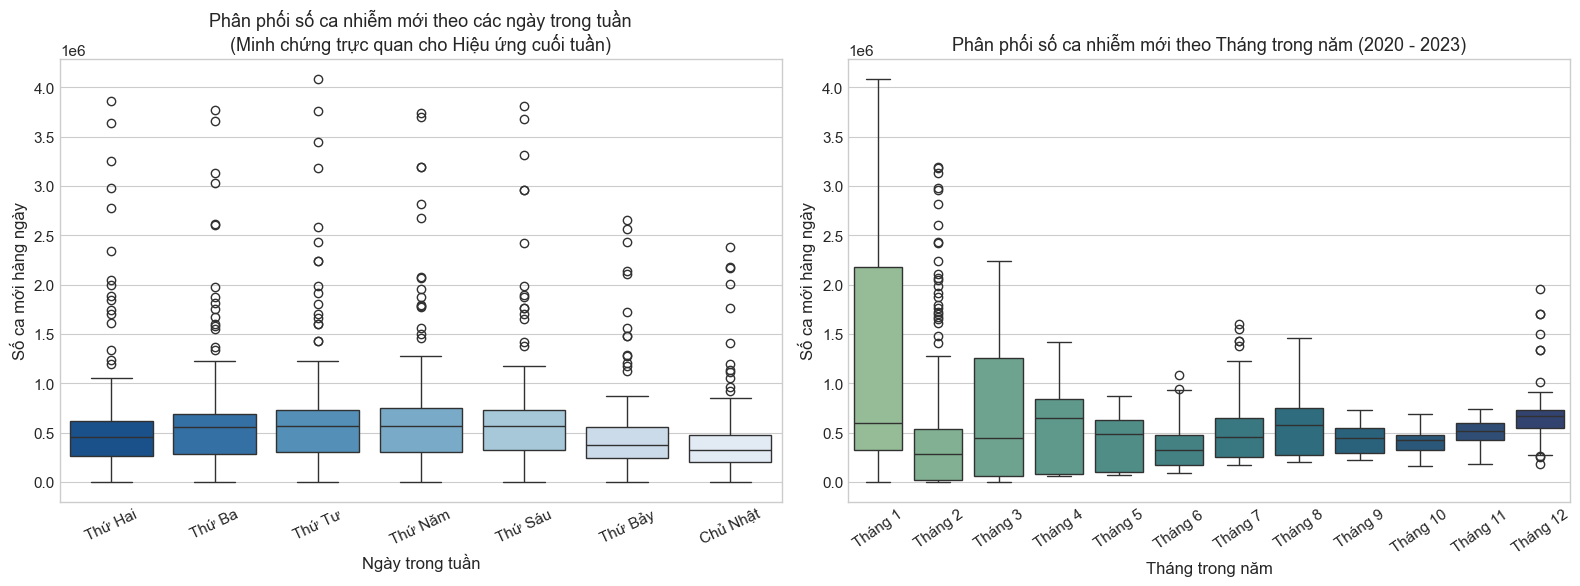

In [8]:
# Trích xuất thứ trong tuần và tháng từ DatetimeIndex
covid_df['DayOfWeek'] = covid_df.index.day_name()
covid_df['Month'] = covid_df.index.month

days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
days_vn = ['Thứ Hai', 'Thứ Ba', 'Thứ Tư', 'Thứ Năm', 'Thứ Sáu', 'Thứ Bảy', 'Chủ Nhật']

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Boxplot phân phối theo thứ trong tuần
sns.boxplot(x='DayOfWeek', y='Daily_Cases', data=covid_df, order=days_order, ax=axes[0], palette='Blues_r')
axes[0].set_xticklabels(days_vn, rotation=25)
axes[0].set_title('Phân phối số ca nhiễm mới theo các ngày trong tuần\n(Minh chứng trực quan cho Hiệu ứng cuối tuần)')
axes[0].set_xlabel('Ngày trong tuần')
axes[0].set_ylabel('Số ca mới hàng ngày')

# 2. Boxplot phân phối theo tháng
month_labels = [f'Tháng {i}' for i in range(1, 13)]
sns.boxplot(x='Month', y='Daily_Cases', data=covid_df, ax=axes[1], palette='crest')
axes[1].set_xticklabels(month_labels, rotation=35)
axes[1].set_title('Phân phối số ca nhiễm mới theo Tháng trong năm (2020 - 2023)')
axes[1].set_xlabel('Tháng trong năm')
axes[1].set_ylabel('Số ca mới hàng ngày')

plt.tight_layout()
plt.show()


#### Nhận xét phân phối theo Thứ & Tháng:
* **Hiệu ứng ngày trong tuần:** Trung vị (Median) và khoảng tứ phân vị của Thứ Bảy & Chủ Nhật thấp rõ rệt so với các ngày giữa tuần. Thứ Ba, Thứ Tư, Thứ Năm là những ngày có lượng báo cáo ca nhiễm trung bình cao nhất trong tuần. Điều này khẳng định tính chu kỳ 7 ngày bắt nguồn từ chu trình làm việc của các cơ sở y tế.
* **Biến thiên theo tháng:** Tháng 1, Tháng 2 ghi nhận phân phối số ca nhiễm vượt trội do mùa đông tại Bắc bán cầu thúc đẩy virus lây lan và thời điểm bùng nổ dịch đầu năm 2022.


### 3.3 Phân tích hàm tự tương quan (ACF) và tự tương quan riêng phần (PACF)
* **ACF (Autocorrelation Function):** Đo lường mối tương quan tuyến tính giữa giá trị hiện tại $y_t$ và các giá trị quá khứ $y_{t-k}$ (bao gồm cả ảnh hưởng trực tiếp và gián tiếp bắc cầu).
* **PACF (Partial Autocorrelation Function):** Đo tương quan trực tiếp giữa $y_t$ và $y_{t-k}$ sau khi đã loại bỏ ảnh hưởng của các bước trễ trung gian.


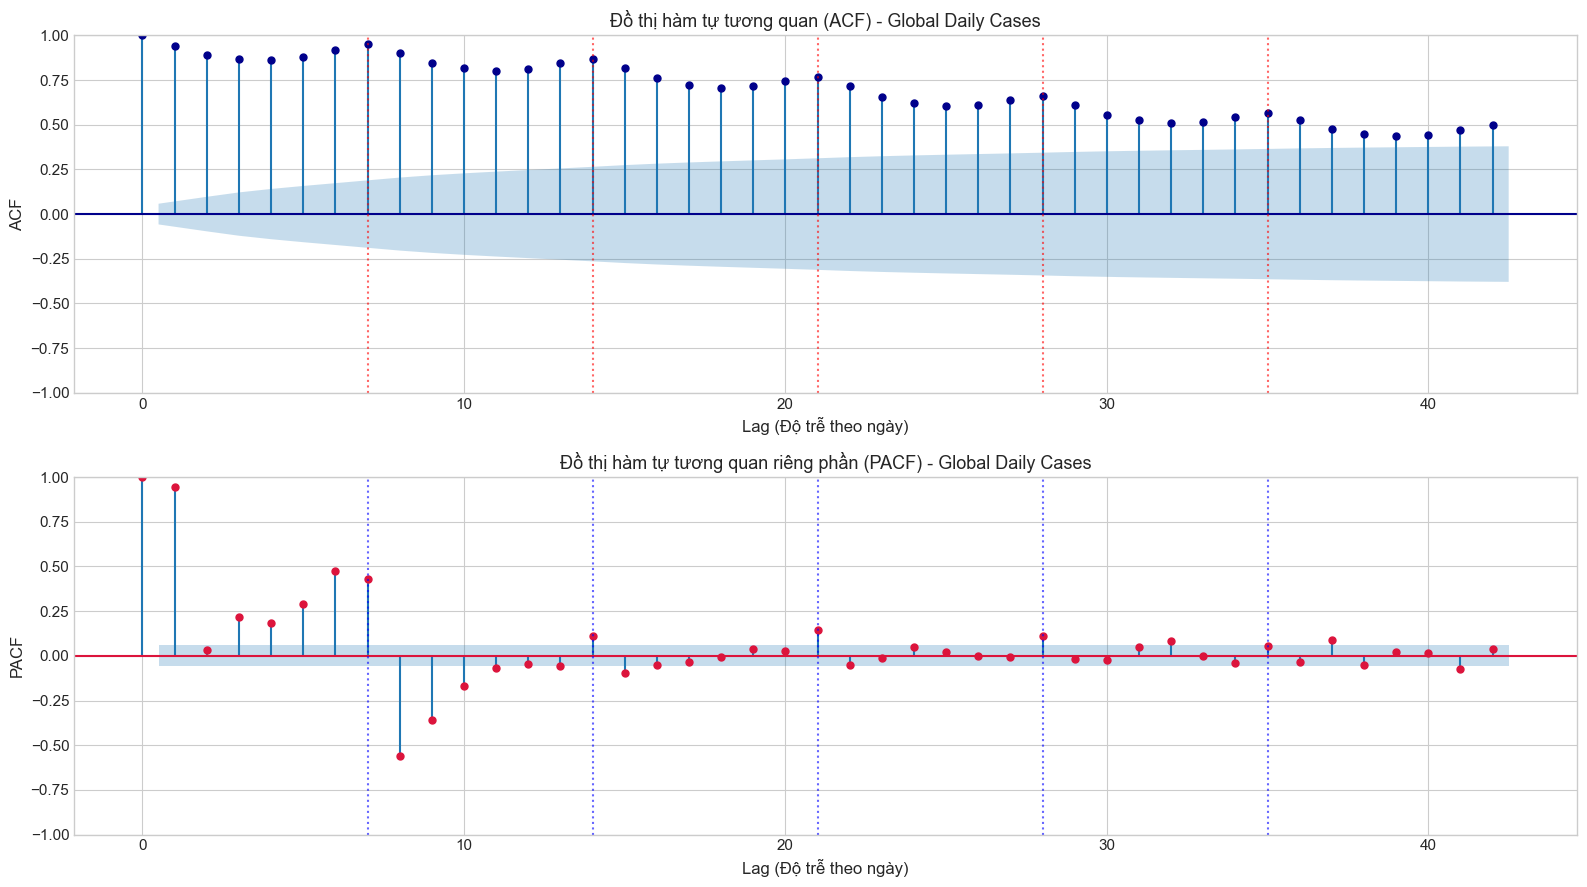

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(16, 9))

# Vẽ đồ thị ACF với 42 lags (tương đương 6 tuần)
plot_acf(covid_df['Daily_Cases'], lags=42, ax=axes[0], alpha=0.05, color='darkblue')
axes[0].set_title('Đồ thị hàm tự tương quan (ACF) - Global Daily Cases')
axes[0].set_xlabel('Lag (Độ trễ theo ngày)')
axes[0].set_ylabel('ACF')

# Đánh dấu các lag bội số của 7
for lag in [7, 14, 21, 28, 35]:
    axes[0].axvline(lag, color='red', linestyle=':', alpha=0.6)

# Vẽ đồ thị PACF
plot_pacf(covid_df['Daily_Cases'], lags=42, ax=axes[1], alpha=0.05, color='crimson', method='ywm')
axes[1].set_title('Đồ thị hàm tự tương quan riêng phần (PACF) - Global Daily Cases')
axes[1].set_xlabel('Lag (Độ trễ theo ngày)')
axes[1].set_ylabel('PACF')
for lag in [7, 14, 21, 28, 35]:
    axes[1].axvline(lag, color='blue', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


#### Nhận xét biểu đồ ACF & PACF:
* **Đặc điểm ACF:** Hệ số tự tương quan khởi đầu ở mức cao ($> 0.9$) và giảm rất chậm theo thời gian, xuất hiện các đỉnh nhọn tuần hoàn định kỳ tại đúng các độ trễ bội số của 7 (Lag 7, 14, 21, 28, 35). Điều này khẳng định chuỗi có Trend mạnh (chưa dừng) và có tính chu kỳ tuần rõ ràng.
* **Đặc điểm PACF:** Hệ số tại Lag 1 và Lag 2 có giá trị rất cao, tiếp tục có đỉnh đáng kể tại Lag 7 rồi tắt dần trong dải tin cậy 95%.


### 3.4 Kiểm định tính phân phối chuẩn của phần dư (Residuals Normality & Q-Q Plot)
Trong lý thuyết chuỗi thời gian, sau khi đã bóc tách Trend và Seasonality, thành phần còn lại là Phần dư (Residuals / Noise) lý tưởng nhất phải là Nhiễu trắng chuẩn (Gaussian White Noise):
$$\epsilon_t \sim \mathcal{N}(0, \sigma^2)$$
Ta kiểm tra tính chất này bằng:
1. **Biểu đồ Histogram & KDE:** So sánh phân phối thực tế của phần dư với đường cong chuẩn lý thuyết.
2. **Q-Q Plot (Quantile-Quantile Plot):** Đánh giá độ bám của các điểm phân vị so với đường phân phối chuẩn $45^\circ$.
3. **Kiểm định Jarque-Bera:** Kiểm tra độ lệch (Skewness) và độ nhọn (Kurtosis).


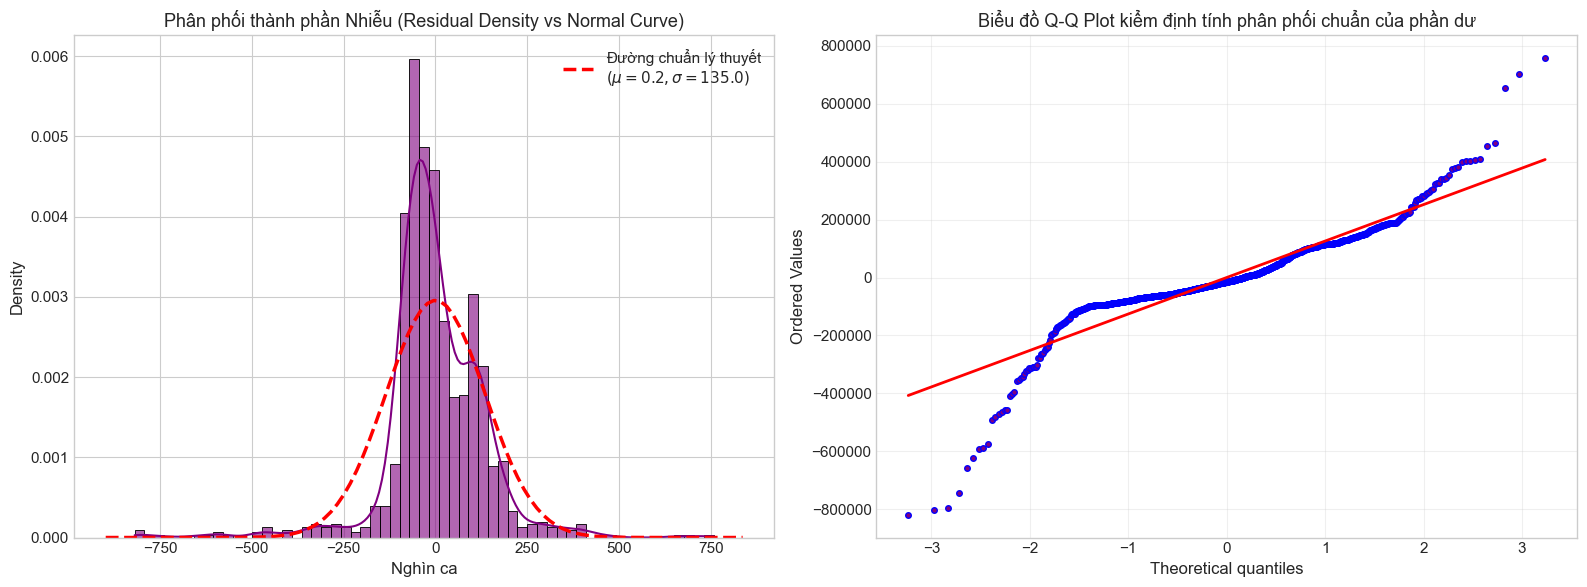

=== KẾT QUẢ KIỂM ĐỊNH TÍNH CHUẨN JARQUE-BERA TRÊN PHẦN DƯ ===
 * Jarque-Bera Statistic : 3,170.71
 * p-value               : 0.00000e+00
 * Độ lệch (Skewness)    : -0.655
 * Độ nhọn (Kurtosis)    : 8.075
 => Kết luận: Phần dư có hiện tượng 'đuôi béo' (Fat-tailed / Leptokurtic) do các đợt bùng dịch đột biến, cần áp dụng Log scale để ổn định.


In [10]:
residuals = decomposition.resid.dropna()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Histogram & KDE của phần dư so với đường chuẩn lý thuyết
sns.histplot(residuals / 1e3, kde=True, ax=axes[0], color='purple', stat='density', alpha=0.6)
mu_res, std_res = stats.norm.fit(residuals / 1e3)
x_axis = np.linspace(axes[0].get_xlim()[0], axes[0].get_xlim()[1], 100)
axes[0].plot(x_axis, stats.norm.pdf(x_axis, mu_res, std_res), 'r--', lw=2.5, 
             label=f'Đường chuẩn lý thuyết\n$(\\mu={mu_res:.1f}, \\sigma={std_res:.1f})$')
axes[0].set_title('Phân phối thành phần Nhiễu (Residual Density vs Normal Curve)')
axes[0].set_xlabel('Nghìn ca')
axes[0].legend(loc='upper right')

# 2. Q-Q Plot
stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].get_lines()[0].set_markerfacecolor('purple')
axes[1].get_lines()[0].set_markersize(4.0)
axes[1].get_lines()[1].set_color('red')
axes[1].get_lines()[1].set_linewidth(2.0)
axes[1].set_title('Biểu đồ Q-Q Plot kiểm định tính phân phối chuẩn của phần dư')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Kiểm định Jarque-Bera
jb_stat, jb_pval = stats.jarque_bera(residuals)
print("=== KẾT QUẢ KIỂM ĐỊNH TÍNH CHUẨN JARQUE-BERA TRÊN PHẦN DƯ ===")
print(f" * Jarque-Bera Statistic : {jb_stat:,.2f}")
print(f" * p-value               : {jb_pval:.5e}")
print(f" * Độ lệch (Skewness)    : {stats.skew(residuals):.3f}")
print(f" * Độ nhọn (Kurtosis)    : {stats.kurtosis(residuals):.3f}")
if jb_pval > 0.05:
    print(" => Kết luận: Phần dư có phân phối chuẩn.")
else:
    print(" => Kết luận: Phần dư có hiện tượng 'đuôi béo' (Fat-tailed / Leptokurtic) do các đợt bùng dịch đột biến, cần áp dụng Log scale để ổn định.")


## 4. BƯỚC 4: KIỂM TRA TÍNH DỪNG (STATIONARITY) & CÁC KỸ THUẬT BIẾN ĐỔI CHUỖI
### 4.1 Khái niệm tính dừng và Kiểm định Augmented Dickey-Fuller (ADF Test)
Một chuỗi thời gian có tính dừng (Stationary) khi:
1. Kỳ vọng trung bình không đổi theo thời gian: $E(y_t) = \mu$.
2. Phương sai không đổi theo thời gian: $\text{Var}(y_t) = \sigma^2$.
3. Hiệp phương sai chỉ phụ thuộc vào khoảng cách độ trễ $k$, không phụ thuộc vào mốc thời gian $t$.

**Kiểm định thống kê ADF Test:**
* Giả thuyết vô hiệu $H_0$: Chuỗi có nghiệm đơn vị (Unit Root) $\implies$ Chuỗi KHÔNG DỪNG (Non-stationary).
* Giả thuyết đối $H_1$: Chuỗi không có nghiệm đơn vị $\implies$ Chuỗi ĐÃ CÓ TÍNH DỪNG (Stationary).
* Quy tắc quyết định: Nếu $p\text{-value} \le 0.05$ (hoặc thống kê ADF < giá trị tới hạn Critical Value tại mức 5%), ta bác bỏ $H_0$ và kết luận chuỗi có tính dừng.


In [11]:
def check_adfuller(series, name="Series"):
    '''
    Hàm kiểm định Augmented Dickey-Fuller và in bảng kết luận khoa học
    '''
    clean_series = series.dropna()
    result = adfuller(clean_series, autolag='AIC')
    
    adf_stat = result[0]
    p_value = result[1]
    lags_used = result[2]
    n_obs = result[3]
    critical_values = result[4]
    
    print(f"=== KẾT QUẢ KIỂM ĐỊNH ADF TEST CHO: [{name}] ===")
    print(f" * Thống kê ADF (ADF Statistic) : {adf_stat:.5f}")
    print(f" * Giá trị p-value               : {p_value:.5e}")
    print(f" * Số độ trễ sử dụng (Lags used): {lags_used}")
    print(f" * Số lượng quan sát (N obs)    : {n_obs}")
    print(" * Các giá trị tới hạn (Critical Values):")
    for key, val in critical_values.items():
        print(f"    - Mức {key:>4}: {val:.4f}")
        
    if p_value <= 0.05:
        print(f" => KẾT LUẬN: p-value = {p_value:.5f} <= 0.05 -> Bác bỏ H0. Chuỗi [{name}] CÓ TÍNH DỪNG (Stationary)!")
    else:
        print(f" => KẾT LUẬN: p-value = {p_value:.5f} > 0.05 -> Chưa đủ cơ sở bác bỏ H0. Chuỗi [{name}] KHÔNG DỪNG (Non-stationary)!")
    print("=" * 60 + "\n")
    
    return {'name': name, 'adf_stat': adf_stat, 'p_value': p_value, 'stationary': p_value <= 0.05}

# Kiểm tra tính dừng cho chuỗi số ca tích lũy và số ca mới hàng ngày
res_cum = check_adfuller(covid_df['Cumulative_Cases'], "Global Cumulative Cases")
res_daily = check_adfuller(covid_df['Daily_Cases'], "Global Daily Cases")


=== KẾT QUẢ KIỂM ĐỊNH ADF TEST CHO: [Global Cumulative Cases] ===
 * Thống kê ADF (ADF Statistic) : 0.00811
 * Giá trị p-value               : 9.59198e-01
 * Số độ trễ sử dụng (Lags used): 21
 * Số lượng quan sát (N obs)    : 1121
 * Các giá trị tới hạn (Critical Values):
    - Mức   1%: -3.4362
    - Mức   5%: -2.8641
    - Mức  10%: -2.5681
 => KẾT LUẬN: p-value = 0.95920 > 0.05 -> Chưa đủ cơ sở bác bỏ H0. Chuỗi [Global Cumulative Cases] KHÔNG DỪNG (Non-stationary)!

=== KẾT QUẢ KIỂM ĐỊNH ADF TEST CHO: [Global Daily Cases] ===
 * Thống kê ADF (ADF Statistic) : -3.04342
 * Giá trị p-value               : 3.10334e-02
 * Số độ trễ sử dụng (Lags used): 20
 * Số lượng quan sát (N obs)    : 1122
 * Các giá trị tới hạn (Critical Values):
    - Mức   1%: -3.4362
    - Mức   5%: -2.8641
    - Mức  10%: -2.5681
 => KẾT LUẬN: p-value = 0.03103 <= 0.05 -> Bác bỏ H0. Chuỗi [Global Daily Cases] CÓ TÍNH DỪNG (Stationary)!



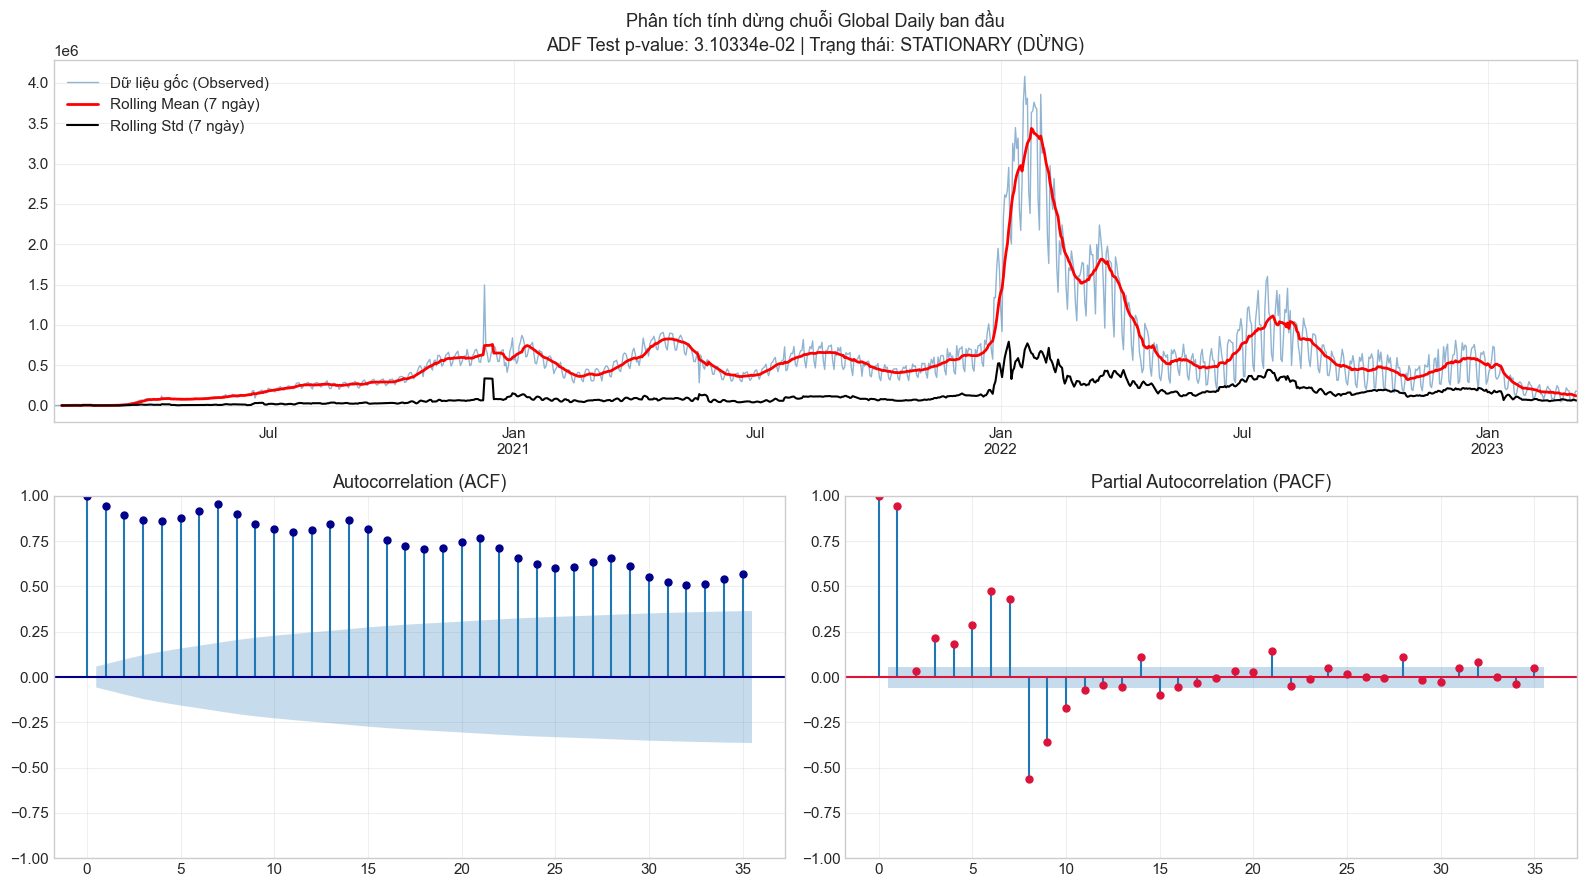

In [12]:
def tsplot(y, lags=35, title='Biểu đồ phân tích tính dừng chuỗi thời gian'):
    '''
    Hàm Dashboard trực quan hóa tổng hợp: Line plot, Rolling Mean/Std, ACF, PACF
    '''
    if not isinstance(y, pd.Series):
        y = pd.Series(y)
    
    y = y.dropna()
    
    fig = plt.figure(figsize=(16, 9))
    layout = (2, 2)
    ts_ax = plt.subplot2grid(layout, (0, 0), colspan=2)
    acf_ax = plt.subplot2grid(layout, (1, 0))
    pacf_ax = plt.subplot2grid(layout, (1, 1))
    
    # 1. Line plot & Rolling stats
    rolmean = y.rolling(window=7).mean()
    rolstd = y.rolling(window=7).std()
    
    y.plot(ax=ts_ax, color='steelblue', label='Dữ liệu gốc (Observed)', alpha=0.6, lw=1)
    rolmean.plot(ax=ts_ax, color='red', label='Rolling Mean (7 ngày)', lw=2)
    rolstd.plot(ax=ts_ax, color='black', label='Rolling Std (7 ngày)', lw=1.5)
    
    p_val = adfuller(y)[1]
    status = "STATIONARY (DỪNG)" if p_val <= 0.05 else "NON-STATIONARY (KHÔNG DỪNG)"
    ts_ax.set_title(f"{title}\nADF Test p-value: {p_val:.5e} | Trạng thái: {status}")
    ts_ax.legend(loc='upper left')
    ts_ax.grid(True, alpha=0.3)
    
    # 2. ACF plot
    plot_acf(y, lags=lags, ax=acf_ax, alpha=0.05, color='darkblue')
    acf_ax.set_title('Autocorrelation (ACF)')
    acf_ax.grid(True, alpha=0.3)
    
    # 3. PACF plot
    plot_pacf(y, lags=lags, ax=pacf_ax, alpha=0.05, color='crimson', method='ywm')
    pacf_ax.set_title('Partial Autocorrelation (PACF)')
    pacf_ax.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Hiển thị Dashboard phân tích tính dừng cho chuỗi Global Daily ban đầu
tsplot(covid_df['Daily_Cases'], lags=35, title='Phân tích tính dừng chuỗi Global Daily ban đầu')


### 4.2 Các kỹ thuật biến đổi đưa chuỗi về trạng thái dừng
Dù chuỗi `Daily_Cases` có dao động quanh trung bình nhưng phương sai thay đổi rất mạnh giữa các thời kỳ và hệ số ACF vẫn dương rất cao do ảnh hưởng của chu kỳ tuần.
Để đưa chuỗi về trạng thái dừng hoàn toàn cả về trung bình và phương sai, ta áp dụng 4 kỹ thuật:
1. **Biến đổi Log scale (Log Transformation):** 
   $$y'_t = \ln(y_t + 1)$$
   Giúp co kéo các đợt bùng phát cực đại, làm ổn định phương sai (Heteroskedasticity $\rightarrow$ Homoskedasticity).
2. **Kỹ thuật Sai phân bậc 1 (First-order Differencing - $d=1$):**
   $$\Delta y_t = y_t - y_{t-1}$$
   Khử triệt để xu hướng tăng giảm dài hạn (Trend).
3. **Kỹ thuật Sai phân mùa vụ (Seasonal Differencing - $D=1, s=7$):**
   $$\Delta_7 y_t = y_t - y_{t-7}$$
   Khử tính chu kỳ tuần lặp lại.
4. **Kỹ thuật Làm mượt (Smoothing with Moving Average):**
   Trừ đi giá trị trung bình trượt 7 ngày để triệt tiêu nhiễu ngắn hạn.


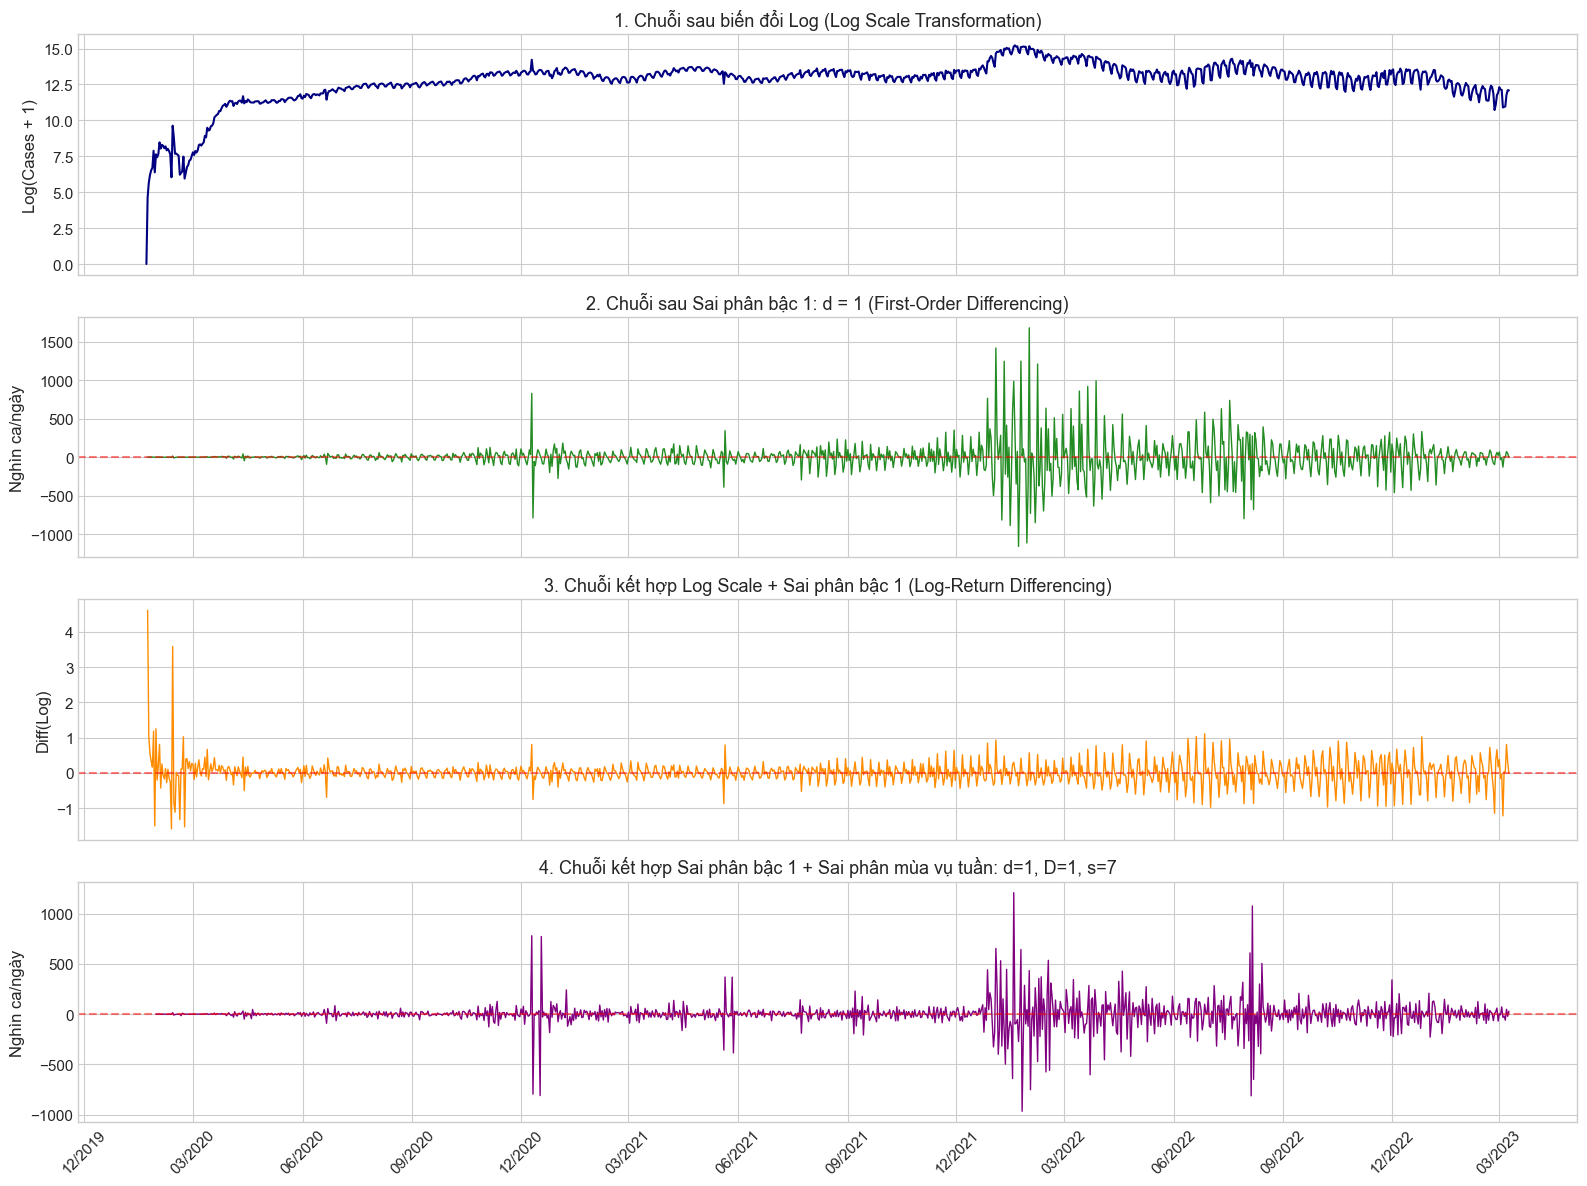

In [13]:
# 1. Biến đổi Log scale
covid_df['Log_Daily'] = np.log1p(covid_df['Daily_Cases'])

# 2. Sai phân bậc 1 trên chuỗi gốc
covid_df['Diff1_Daily'] = covid_df['Daily_Cases'].diff()

# 3. Sai phân bậc 1 trên chuỗi Log (Log-Difference)
covid_df['Log_Diff1_Daily'] = covid_df['Log_Daily'].diff()

# 4. Sai phân bậc 1 kết hợp sai phân mùa vụ 7 ngày (Seasonal Differencing)
covid_df['Seasonal_Diff_Daily'] = covid_df['Diff1_Daily'].diff(7)

# 5. Làm mượt bằng Moving Average: Lấy chuỗi trừ đi Rolling Mean 7 ngày
covid_df['MA_Residual_Daily'] = covid_df['Daily_Cases'] - covid_df['Daily_Cases_7d_MA']

# So sánh các chuỗi sau biến đổi
fig, axes = plt.subplots(4, 1, figsize=(16, 12), sharex=True)

axes[0].plot(covid_df.index, covid_df['Log_Daily'], color='navy', lw=1.5)
axes[0].set_title('1. Chuỗi sau biến đổi Log (Log Scale Transformation)')
axes[0].set_ylabel('Log(Cases + 1)')

axes[1].plot(covid_df.index, covid_df['Diff1_Daily'] / 1e3, color='forestgreen', lw=1)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[1].set_title('2. Chuỗi sau Sai phân bậc 1: d = 1 (First-Order Differencing)')
axes[1].set_ylabel('Nghìn ca/ngày')

axes[2].plot(covid_df.index, covid_df['Log_Diff1_Daily'], color='darkorange', lw=1)
axes[2].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[2].set_title('3. Chuỗi kết hợp Log Scale + Sai phân bậc 1 (Log-Return Differencing)')
axes[2].set_ylabel('Diff(Log)')

axes[3].plot(covid_df.index, covid_df['Seasonal_Diff_Daily'] / 1e3, color='purple', lw=1)
axes[3].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[3].set_title('4. Chuỗi kết hợp Sai phân bậc 1 + Sai phân mùa vụ tuần: d=1, D=1, s=7')
axes[3].set_ylabel('Nghìn ca/ngày')

axes[3].xaxis.set_major_locator(mdates.MonthLocator(interval=3))
axes[3].xaxis.set_major_formatter(mdates.DateFormatter('%m/%Y'))
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


BẢNG SO SÁNH HIỆU QUẢ CỦA CÁC PHÉP BIẾN ĐỔI LÀM DỪNG:


,Kỹ thuật biến đổi,ADF Statistic,p-value,Ngưỡng 5% Critical,Tính dừng (Stationary)
0,Chuỗi gốc (Daily Cases),-3.0434,3.103341e-02,-2.8641,ĐẠT (DỪNG)
1,Log Transform,-4.4286,2.641214e-04,-2.8641,ĐẠT (DỪNG)
2,Sai phân bậc 1 (d = 1),-6.6616,4.830647e-09,-2.8641,ĐẠT (DỪNG)
3,Log + Sai phân bậc 1,-7.2603,1.688820e-10,-2.8641,ĐẠT (DỪNG)
4,"Sai phân bậc 1 + Sai phân tuần (d=1, D=1, s=7)",-6.9795,8.263872e-10,-2.8641,ĐẠT (DỪNG)
5,Smoothing trừ Moving Average 7d,-6.9829,8.106019e-10,-2.8641,ĐẠT (DỪNG)


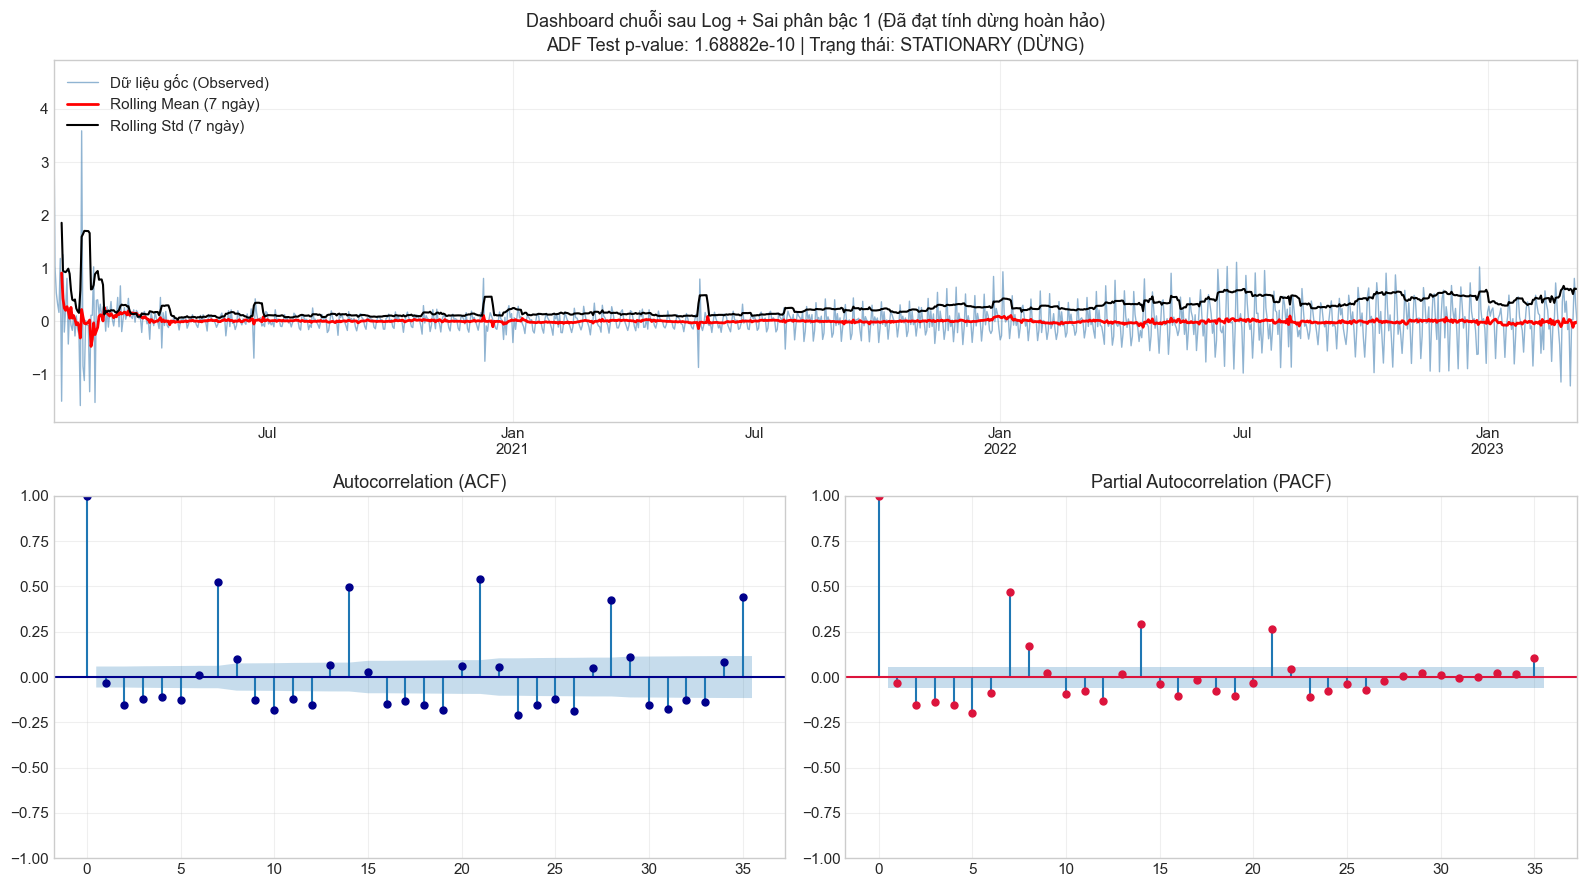

In [14]:
# Kiểm định lại ADF test trên tất cả các chuỗi sau biến đổi
transformations = [
    ('Chuỗi gốc (Daily Cases)', covid_df['Daily_Cases']),
    ('Log Transform', covid_df['Log_Daily']),
    ('Sai phân bậc 1 (d = 1)', covid_df['Diff1_Daily']),
    ('Log + Sai phân bậc 1', covid_df['Log_Diff1_Daily']),
    ('Sai phân bậc 1 + Sai phân tuần (d=1, D=1, s=7)', covid_df['Seasonal_Diff_Daily']),
    ('Smoothing trừ Moving Average 7d', covid_df['MA_Residual_Daily'])
]

summary_results = []
for name, s in transformations:
    clean_s = s.dropna()
    res = adfuller(clean_s, autolag='AIC')
    summary_results.append({
        'Kỹ thuật biến đổi': name,
        'ADF Statistic': round(res[0], 4),
        'p-value': res[1],
        'Ngưỡng 5% Critical': round(res[4]['5%'], 4),
        'Tính dừng (Stationary)': 'ĐẠT (DỪNG)' if res[1] <= 0.05 else 'CHƯA DỪNG'
    })

comparison_df = pd.DataFrame(summary_results)
print("BẢNG SO SÁNH HIỆU QUẢ CỦA CÁC PHÉP BIẾN ĐỔI LÀM DỪNG:")
display(comparison_df)

# Hiển thị Dashboard hoàn thiện cho chuỗi Log + Sai phân bậc 1
tsplot(covid_df['Log_Diff1_Daily'], lags=35, title='Dashboard chuỗi sau Log + Sai phân bậc 1 (Đã đạt tính dừng hoàn hảo)')


In [15]:
# Xuất bộ dữ liệu sạch đã tạo đặc trưng thời gian ra file CSV để dùng cho File 2 (Modeling & Forecasting)
output_clean_csv = "covid_daily_clean.csv"
covid_df.to_csv(output_clean_csv)
print(f"Đã xuất dữ liệu sạch sang file: {output_clean_csv} ({os.path.getsize(output_clean_csv):,} bytes)")


Đã xuất dữ liệu sạch sang file: covid_daily_clean.csv (149,933 bytes)
